In [1]:
import pandas as pd
import random
import pickle
import torch.nn as nn
import torch
import torch.nn.functional as F
import numpy as np
from sb import model_bu
from sklearn.preprocessing import MinMaxScaler
from visualize import *
from data_generation import *   
from preprocessing_bu import *
from loss import *
import math

seed = 420
torch.manual_seed(seed)
np.random.seed(seed)
random.seed(seed)
torch.cuda.manual_seed_all(seed)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

100%|██████████| 1/1 [00:00<00:00, 140.52it/s]


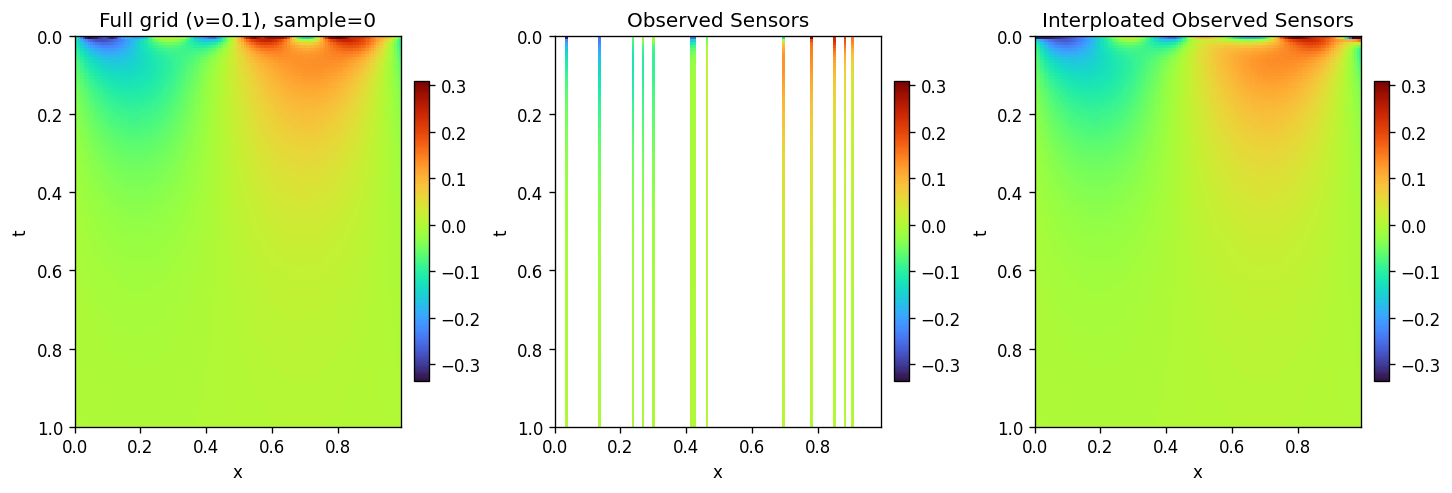

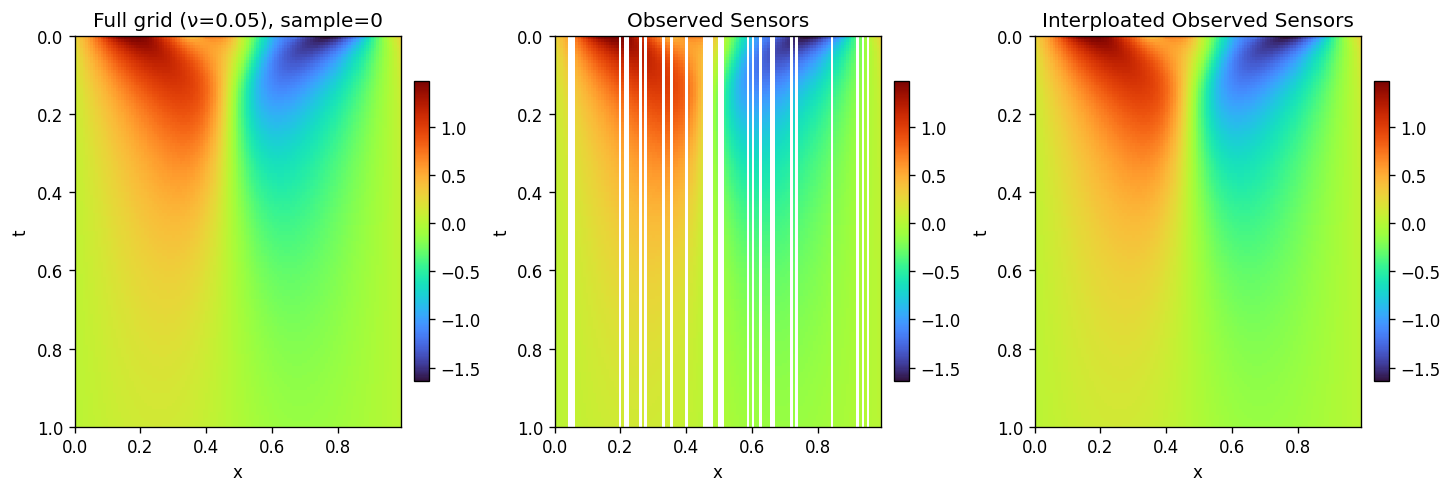

In [9]:
high_resol_coef = 0.1
low_resol_coef = 0.05

data1 = generate_dataset(
    n_samples=1,
    nu=high_resol_coef,    
    Nx=128,    
    Nt=128, 
    T=1.0,
    L=1.0,
    grf_type="periodic",
    n_sensors=13,
    fixed_sensors=True,
    seed=0,
)
data2 = generate_dataset(
    n_samples=1,
    nu=low_resol_coef,    
    Nx=128,    
    Nt=128, 
    T=1.0,
    L=1.0,
    grf_type="periodic",
    n_sensors=100,
    fixed_sensors=True,
    seed=20,
)
data1 = fill_missing_with_cubic_interp(data1)
data2 = fill_missing_with_cubic_interp(data2)
plot_full_and_observed_heatmaps(data1, sample_idx=0)
plot_full_and_observed_heatmaps(data2, sample_idx=0)

In [10]:
((np.abs(data2['U_full'] - data2['U_filled']))**2).mean()

1.6776923e-07

In [11]:
WA, WB, starts = make_paired_time_window_dataset(
    data1, # full grid 줄 친구
    data2, # 일부 센서만 줄 친구
    win_T=128,
    stride=128,
    start_t=0,
    end_t=None,
)
print(burgers_pde_mse(torch.tensor(data1['U_full']), high_resol_coef), burgers_pde_mse(torch.tensor(data2['U_full']), low_resol_coef))
print(burgers_pde_mse(torch.tensor(data2['U_filled']), low_resol_coef))
sensor_mask = torch.from_numpy(data2["mask"]).float()
sensor_mask = sensor_mask.view(1, 1, 1, -1)
WB_mask = sensor_mask.repeat(WB.shape[0], 1, WB.shape[2], 1)
mask_list = [None, WB_mask]

print(WA.shape, WB.shape)

WA_scaled, WB_scaled = flatten(WA, WB)
print(WA_scaled.shape, WB_scaled.shape)
# WA_scaled *= 3
# WB_scaled *= 10
# WA *= 3
# WB *= 10

tensor(0.0143) tensor(0.0134)
tensor(0.0139)
torch.Size([1, 1, 128, 128]) torch.Size([1, 1, 128, 128])
torch.Size([1, 16384]) torch.Size([1, 16384])


In [12]:
steps = 10
eps_train = 0.01
eps_test = 0.01
sb_object = model_bu.sb_muti_model([WA, WB],[0,1],N_train=3000, base_lr=1e-3,
                              steps=steps,eps_train=eps_train,eps_test=eps_test,patience=500,B=WA_scaled.shape[0],lambda_=1e-3,clamp=False,save=True, mask_list=mask_list)


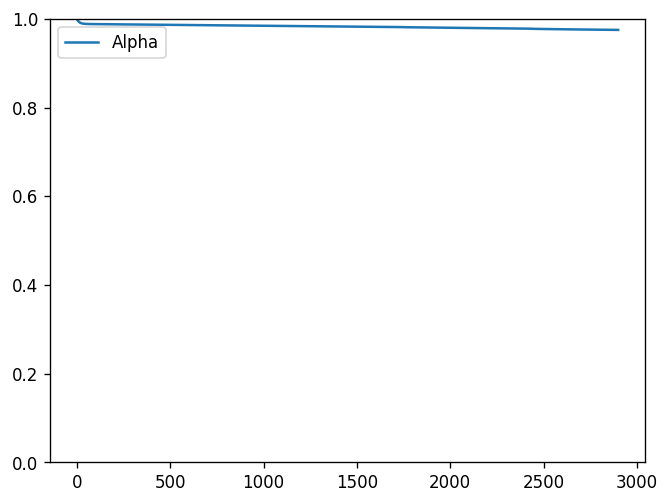

processed: 3000: 100%|██████████| 3000/3000 [01:11<00:00, 41.67it/s, MSE_observed=0.7199297, PDE_loss=1111.9636, PDE_loss2=18.718466, Alpha=[0.9746063]]   


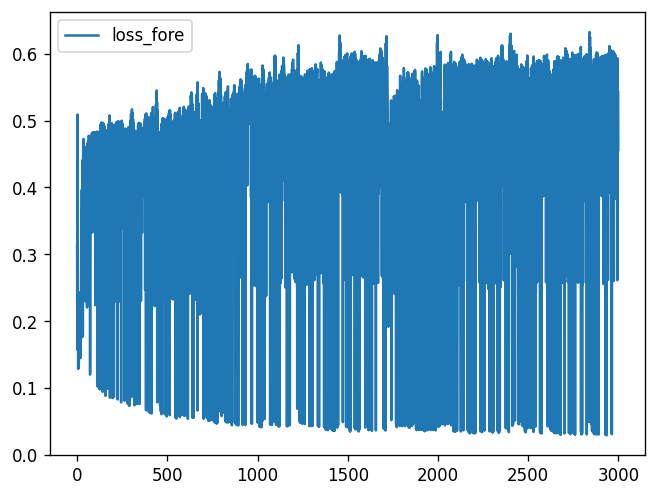

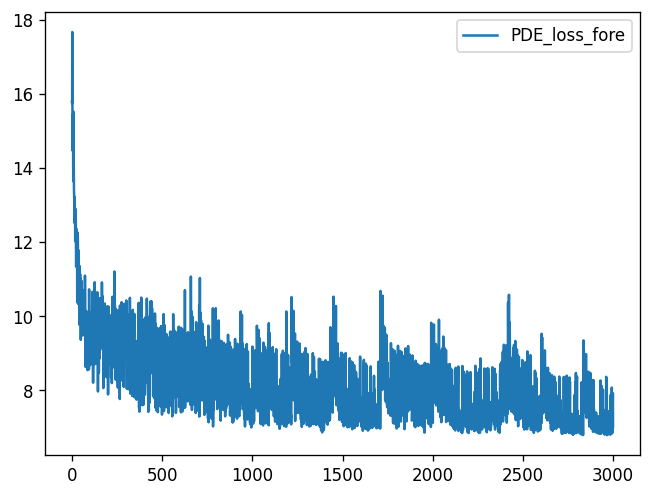

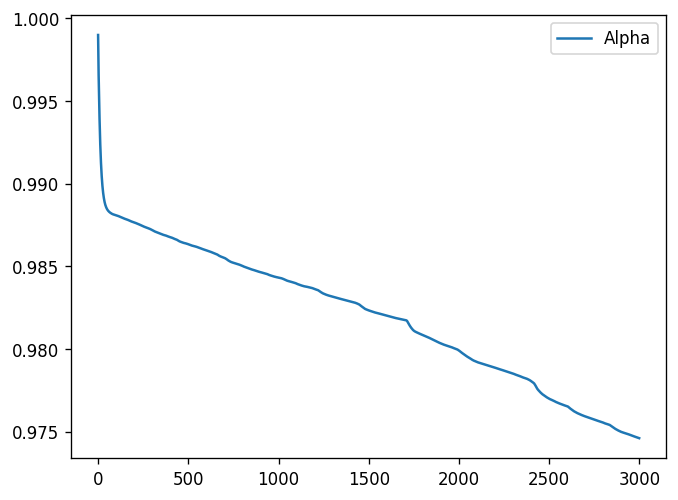

In [13]:
sb_object.train(low_resol_coef)

In [14]:
sb_object.finetuning_load('model_bu/finetuning_end.pt')

In [15]:
# eps_test = 0.01
# sb_object.steps = 60
predict = sb_object.eval_fore(x_0 = WA_scaled, x_1_fixed = (WB * WB_mask), mask=WB_mask, eps_test=0)
predict = predict[-1].detach().cpu().numpy()
predict = torch.from_numpy(predict)
predict = stitch_windows(predict, starts, win_T=128, Nx=128, stride=128)

In [16]:
(np.abs(data2['U_full'].squeeze(0).squeeze(0)[:, data2['mask']] - predict.detach().cpu().numpy()[:, data2['mask']])**2).mean()

0.0

In [17]:
(np.abs(data2['U_full'].squeeze(0).squeeze(0) - predict.detach().cpu().numpy())**2).mean()

7.725213e-06

In [18]:
burgers_pde_mse_observed_pixel(predict.unsqueeze(0).unsqueeze(0), low_resol_coef, WB_mask)

tensor(0.4263)

In [19]:
burgers_pde_mse(predict.unsqueeze(0).unsqueeze(0), low_resol_coef)

tensor(1.2151)

In [20]:
burgers_pde_mse(predict.unsqueeze(0).unsqueeze(0), sb_object.alpha.to('cpu'))

tensor(1255.8441, grad_fn=<MeanBackward0>)

In [21]:
def generate_dataset(
    n_samples: int,
    nu: float = 0.01,
    Nx: int = 128,
    Nt: int = 128,
    T: float = 1.0,
    L: float = 1.0,
    # GRF1 params
    grf_N: int = None,
    grf_m: float = 0.0,
    grf_gamma: float = 2.0,
    grf_tau: float = 5.0,
    grf_sigma: float = 25.0,
    grf_type: str = "periodic",
    # sensors
    n_sensors: int = 5,
    fixed_sensors: bool = False,
    seed: int = 0,
) :

    rng = np.random.default_rng(seed)

    x = np.linspace(0.0, L, Nx, endpoint=False).astype(np.float32)
    t = np.linspace(0.0, T, Nt).astype(np.float32)

    # 🔑 이미지 텐서로 바로 생성
    U_full = np.zeros((n_samples, 1, Nt, Nx), dtype=np.float32)
    U_obs  = np.zeros((n_samples, 1, Nt, Nx), dtype=np.float32)
    U0     = np.zeros((n_samples, 1, 1, Nx), dtype=np.float32)

    if grf_N is None:
        grf_N = Nx // 2

    if fixed_sensors:
        mask = make_sensor_mask(Nx, n_sensors=n_sensors, rng=np.random.default_rng(seed+1))
    else:
        mask = np.zeros((n_samples, Nx), dtype=bool)

    for i in tqdm(range(n_samples)):
        # ---- Initial condition (1D field)
        u0 = predict[0,:].detach().cpu().numpy()
        # ---- Burgers solve → (Nt, Nx)
        U = solve_burgers_1d(
            u0=u0,
            nu=nu,
            Nx=Nx,
            Nt=Nt,
            T=T,
            L=L,
            dealias=True,
        )

        # ---- Store as images
        U_full[i, 0] = U
        U0[i, 0, 0]  = u0

        if fixed_sensors:
            U_obs_i = apply_spatial_mask(U, mask)
        else:
            msk = make_sensor_mask(Nx, n_sensors=n_sensors, rng=rng)
            mask[i] = msk
            U_obs_i = apply_spatial_mask(U, msk)

        # NaN 유지 (or 여기서 0으로 바꿔도 됨)
        U_obs[i, 0] = U_obs_i

    return {
        "x": x,
        "t": t,
        "nu": np.asarray(nu, dtype=np.float32),
        "U_full": U_full,   # (N, 1, Nt, Nx)
        "U_obs": U_obs,     # (N, 1, Nt, Nx)
        "u0": U0,           # (N, 1, 1, Nx)
        "mask": mask,
        "grf_params": np.asarray(
            [grf_N, grf_m, grf_gamma, grf_tau, grf_sigma],
            dtype=np.float32,
        ),
    }

data22 = generate_dataset(
    n_samples=1,
    nu=low_resol_coef,    
    Nx=128,    
    Nt=128, 
    T=1.0,
    L=1.0,
    grf_type="periodic",
    n_sensors=2,
    fixed_sensors=True,
    seed=20,
)

100%|██████████| 1/1 [00:00<00:00, 175.43it/s]


In [22]:
data22['U_full']

array([[[[0.31060064, 0.34958884, 0.3984034 , ..., 0.16412635,
          0.2306696 , 0.28156814],
         [0.28948984, 0.33720598, 0.38474137, ..., 0.13782339,
          0.19045796, 0.24081177],
         [0.27111858, 0.32054374, 0.3698699 , ..., 0.1181028 ,
          0.17027391, 0.22116238],
         ...,
         [0.02205943, 0.02743867, 0.03278625, ..., 0.00579737,
          0.01123229, 0.01665513],
         [0.02177958, 0.02708819, 0.03236518, ..., 0.0057296 ,
          0.0110938 , 0.01644594],
         [0.02150302, 0.02674181, 0.03194903, ..., 0.00566273,
          0.010957  , 0.01623925]]]], dtype=float32)

In [ ]:
plot_result(
    data1['U_full'],
    data2['U_full'],
    predict,
    cmap="turbo",
    high_resol_coef=high_resol_coef,
    low_resol_coef=low_resol_coef,
    mask_1d=data2['mask']
)

RuntimeError: Expected 3D (unbatched) or 4D (batched) input to conv2d, but got input of size: [1, 1]